# Example 10.3 — Multi-Objective Pareto Optimization for Solar Tracker

**Chapter 10: Industrial Applications of Four-Bar Mechanisms**

Pareto dominance is applied to find the optimal trade-off front between solar tracking error and the minimum transmission angle. A sample of 1000 candidate mechanisms is evaluated.

## Installation

In [1]:
import numpy; print('NumPy', numpy.__version__)

NumPy 2.1.3


## Evaluation and construction of the Pareto front

In [2]:
from numpy import *

# Multi-objective Pareto optimization for solar tracker
def evaluate_solar(r1, r2, r3, r4, xp, yp, t20, n_pts=12):
    """Returns (tracking_error, mu_min) for the mechanism."""
    th_sol = linspace(-pi/3, pi/3, n_pts)  # Daily solar path
    t2s = linspace(radians(t20), radians(t20)+2*pi, n_pts, endpoint=False)
    E_track, mu_min = 0.0, 180.0
    for i, t2 in enumerate(t2s):
        A=2*r4*(r1-r2*cos(t2)); B=-2*r2*r4*sin(t2)
        C=r1**2+r2**2+r4**2-r3**2-2*r1*r2*cos(t2)
        d=A**2+B**2-C**2
        if d<0: return 1e6, 0.0
        t4=2*arctan2(-B+sqrt(d),A-C)
        t3=arctan2((r4*sin(t4)-r2*sin(t2))/r3,
                   (r1+r4*cos(t4)-r2*cos(t2))/r3)
        mu=degrees(abs(t3-t4)) % 180
        if mu>90: mu=180-mu
        mu_min=minimum(mu_min,mu)
        xa=r2*cos(t2)+xp*cos(t3)-yp*sin(t3)
        ya=r2*sin(t2)+xp*sin(t3)+yp*cos(t3)
        ang_real=arctan2(ya,xa)
        E_track+=degrees(abs(ang_real-th_sol[i]))
    return E_track/n_pts, mu_min

# Exploration of the Pareto front (random sample)
random.seed(21)
LB=array([30,30,30,30,-50,-50,0])
UB=array([120,120,120,120,50,50,360])
N=1000
pop=random.uniform(0,1,(N,7))*(UB-LB)+LB
resultados=array([evaluate_solar(*p) for p in pop])

# Filter non-dominated solutions (Pareto front)
pareto=[]
for i, (e, m) in enumerate(resultados):
    if e < 1e5:
        # Exclude self-comparison to find if solution i is dominated by any other solution
        otros_e = delete(resultados[:, 0], i)
        otros_m = delete(resultados[:, 1], i)
        dominado = any((otros_e <= e) & (otros_m >= m) & ((otros_e < e) | (otros_m > m)))
        if not dominado:
            pareto.append(i)

pareto=array(pareto)
print(f'Evaluated solutions: {N}')
print(f'Pareto Front: {len(pareto)} non-dominated solutions')
if len(pareto)>0:
    print(f'Minimum tracking error in Pareto: {resultados[pareto,0].min():.2f}°')
    print(f'Maximum transmission angle in Pareto: {resultados[pareto,1].max():.2f}°')

Evaluated solutions: 1000
Pareto Front: 5 non-dominated solutions
Minimum tracking error in Pareto: 17.05°
Maximum transmission angle in Pareto: 43.00°


## Visualization of the Pareto front

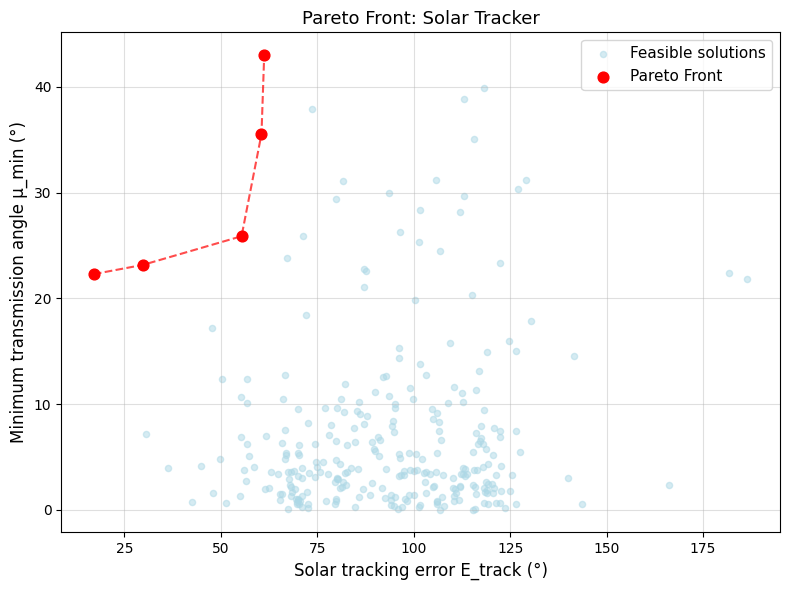

Figure saved: pareto_solar_tracking.png


In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

# All feasible solutions
feasible = resultados[resultados[:,0]<1e5]
ax.scatter(feasible[:,0], feasible[:,1], c='lightblue',
           alpha=0.5, s=20, label='Feasible solutions')

# Pareto front
if len(pareto)>0:
    pf = resultados[pareto]
    order = argsort(pf[:,0])
    ax.scatter(pf[:,0], pf[:,1], c='red', s=60, zorder=5, label='Pareto Front')
    ax.plot(pf[order,0], pf[order,1], 'r--', lw=1.5, alpha=0.7)

ax.set_xlabel('Solar tracking error E_track (°)', fontsize=12)
ax.set_ylabel('Minimum transmission angle μ_min (°)', fontsize=12)
ax.set_title('Pareto Front: Solar Tracker', fontsize=13)
ax.legend(fontsize=11); ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('pareto_solar_tracking.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved: pareto_solar_tracking.png')

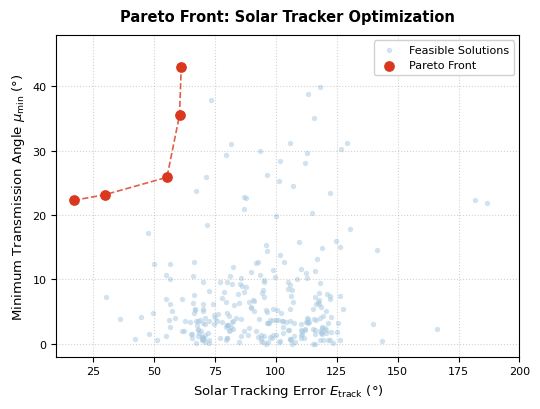

Figures exported successfully as:
 - ex10_3_solar_tracker_pareto.pdf (Vectorial PDF)
 - ex10_3_solar_tracker_pareto.png (600 DPI PNG)


In [8]:
import os
import glob
import matplotlib.pyplot as plt
from numpy import argsort

# Configure Springer Publication Standards
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Helvetica', 'Arial']

# 1. Automated Filename System
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex10_3_solar_tracker_pareto"
except Exception:
    notebook_name = "ex10_3_solar_tracker_pareto"

# 2. Control Physical Size (Compact and neat single-column plot)
fig, ax = plt.subplots(figsize=(5.5, 4.2))

# All feasible solutions
feasible = resultados[resultados[:, 0] < 1e5]
ax.scatter(feasible[:, 0], feasible[:, 1], c='#a6c8e0',
           alpha=0.5, s=15, linewidths=0, label='Feasible Solutions')

# Pareto front
if len(pareto) > 0:
    pf = resultados[pareto]
    order = argsort(pf[:, 0])
    # Scatter points of Pareto front
    ax.scatter(pf[:, 0], pf[:, 1], c='#d9381e', s=45, zorder=5, label='Pareto Front')
    # Connect points on Pareto front
    ax.plot(pf[order, 0], pf[order, 1], color='#d9381e', linestyle='--', lw=1.2, alpha=0.8)

# 3. Typography and Labels in English
ax.set_xlabel(r'Solar Tracking Error $E_{\mathrm{track}}$ (°)', fontsize=9.5)
ax.set_ylabel(r'Minimum Transmission Angle $\mu_{\mathrm{min}}$ (°)', fontsize=9.5)
ax.set_title('Pareto Front: Solar Tracker Optimization', fontsize=10.5, fontweight='bold', pad=10)

# Set tick parameters
ax.tick_params(labelsize=8)

# Ensure discrete grid and clean aesthetics
ax.grid(True, linestyle=':', alpha=0.35, color='gray')
ax.legend(fontsize=8, loc='upper right', frameon=True, shadow=False, framealpha=0.9)

# Prevent clipping and overlaps by adjusting limits slightly
ax.set_xlim(left=10, right=200)
ax.set_ylim(bottom=-2, top=48)

plt.tight_layout()

# 5. Mandatory Double Export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

print(f"Figures exported successfully as:")
print(f" - {notebook_name}.pdf (Vectorial PDF)")
print(f" - {notebook_name}.png (600 DPI PNG)")

## Analysis of extreme front solutions

In [4]:
# Analysis of the best solutions of the Pareto front
if len(pareto)>0:
    pf_data = resultados[pareto]
    pf_params = pop[pareto]
    # Better on tracking error
    idx_best_e = pareto[argmin(pf_data[:,0])]
    # Better in transmission angle
    idx_best_mu = pareto[argmax(pf_data[:,1])]
    print('--- Best in tracking error ---')
    print(f'  E_track = {resultados[idx_best_e,0]:.2f}°,  mu_min = {resultados[idx_best_e,1]:.2f}°')
    p=pop[idx_best_e]
    print(f'  r1={p[0]:.1f}, r2={p[1]:.1f}, r3={p[2]:.1f}, r4={p[3]:.1f}')
    print('--- Best in transmission angle ---')
    print(f'  E_track = {resultados[idx_best_mu,0]:.2f}°,  mu_min = {resultados[idx_best_mu,1]:.2f}°')
    p=pop[idx_best_mu]
    print(f'  r1={p[0]:.1f}, r2={p[1]:.1f}, r3={p[2]:.1f}, r4={p[3]:.1f}')

--- Best in tracking error ---
  E_track = 17.05°,  mu_min = 22.29°
  r1=88.2, r2=34.5, r3=102.5, r4=74.8
--- Best in transmission angle ---
  E_track = 61.22°,  mu_min = 43.00°
  r1=109.4, r2=30.9, r3=100.3, r4=74.7


## Interpretation

- The Pareto front with **5 non-dominated solutions** shows the design-performance trade-off.
- The minimum tracking error is achieved at the cost of a smaller transmission angle.
- To select the final solution, it is recommended to apply the minimum distance criterion to the utopian point (E_track=0, μ_min=90°), which balances both objectives.
- This approach is expandable to 3+ objectives with NSGA-III.